In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score,learning_curve, train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import auc,confusion_matrix, roc_curve, classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler

In [6]:
df=pd.read_csv('/content/dataset.csv',sep=";")
df.describe(include='all')

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graduate
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2209
mean,1.178571,6.886980,1.727848,9.899186,0.890823,2.531420,1.254521,12.322107,16.455244,7.317812,...,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969,NaN
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.044800,3.997828,...,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935,NaN
min,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000,NaN
25%,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,2.000000,3.000000,5.000000,...,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000,NaN
50%,1.000000,8.000000,1.000000,10.000000,1.000000,1.000000,1.000000,13.000000,14.000000,6.000000,...,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000,NaN
75%,1.000000,12.000000,2.000000,13.000000,1.000000,1.000000,1.000000,22.000000,27.000000,10.000000,...,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000,NaN


In [7]:
df.isnull().sum()

,0
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Nacionality,0
Mother's qualification,0
Father's qualification,0
Mother's occupation,0


/tmp/ipykernel_8204/264826426.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df.Target,palette=["purple", "orange","red"])


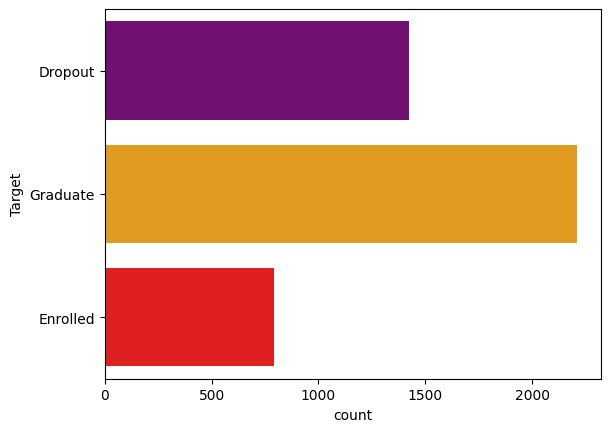

,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


In [14]:
sns.countplot(df.Target,palette=["purple", "orange","red"])
plt.show()
df.Target.value_counts()

In [15]:
df['Target']=df.Target.map(dict(Dropout=0,Graduate=1,Enrolled=2))

In [17]:
df=df[df['Target']!=2]
df['Target']

,Target
0,0
1,1
2,0
3,1
4,1
...,...
4419,1
4420,0
4421,0
4422,1


In [19]:
x=df.drop('Target',axis=1)
y=df['Target']
x.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3630 entries, 0 to 4423
Data columns (total 34 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  3630 non-null   int64  
 1   Application mode                                3630 non-null   int64  
 2   Application order                               3630 non-null   int64  
 3   Course                                          3630 non-null   int64  
 4   Daytime/evening attendance                      3630 non-null   int64  
 5   Previous qualification                          3630 non-null   int64  
 6   Nacionality                                     3630 non-null   int64  
 7   Mother's qualification                          3630 non-null   int64  
 8   Father's qualification                          3630 non-null   int64  
 9   Mother's occupation                           

kbest chois best feature to target you detrmind the number of col ke sure all el is +

In [20]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
x=scaler.fit_transform(x)


In [26]:
from sklearn.feature_selection import SelectKBest,chi2
bestfeatures=SelectKBest(chi2,k=15)
x=bestfeatures.fit_transform(x,y)
x.shape


(3630, 15)

<Axes: >

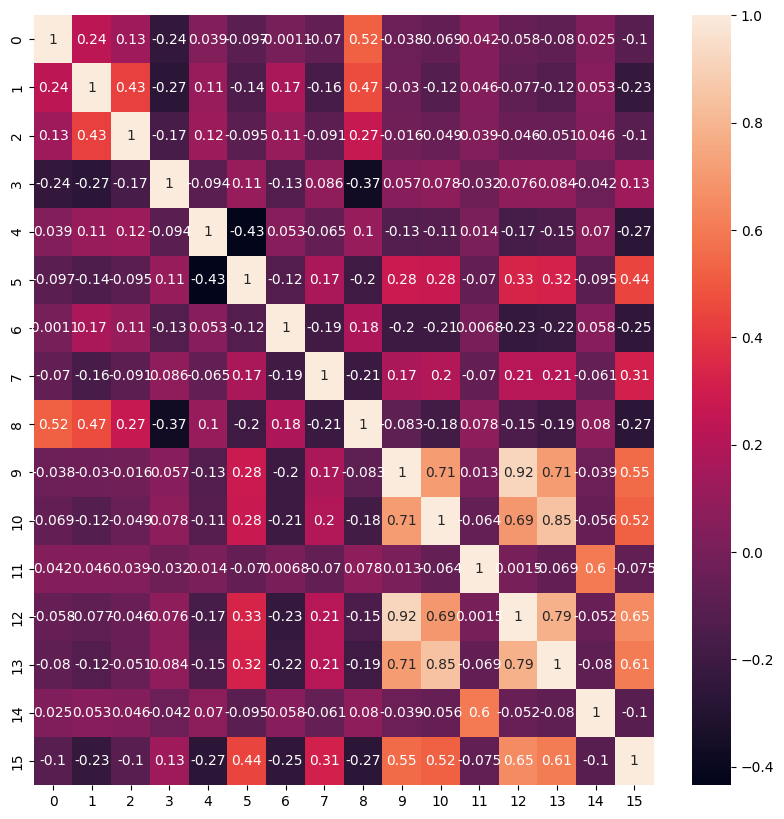

In [31]:
df=np.column_stack([x,y])
df=pd.DataFrame(df)
f,ax=plt.subplots(figsize=(10,10))
sns.heatmap(df.corr(),annot=True)


In [32]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=.2,random_state=42)

In [34]:
model = DecisionTreeClassifier(random_state=42)
params = {'splitter': ["best", "random"],
          'max_depth': np.arange(1,10,1),
          'min_samples_leaf': np.arange(1,5,1),
          'min_samples_split': np.arange(2,5,1)
         }
cv_dt = GridSearchCV(model, param_grid=params, scoring="accuracy", n_jobs=-1,cv=5)
cv_dt.fit(xtrain, ytrain)
best_DT=cv_dt.best_estimator_
y_pred = best_DT.predict(xtest)
print(cv_dt.best_params_, cv_dt.best_score_)

{'max_depth': np.int64(3), 'min_samples_leaf': np.int64(1), 'min_samples_split': np.int64(2), 'splitter': 'random'} 0.8880829722832214


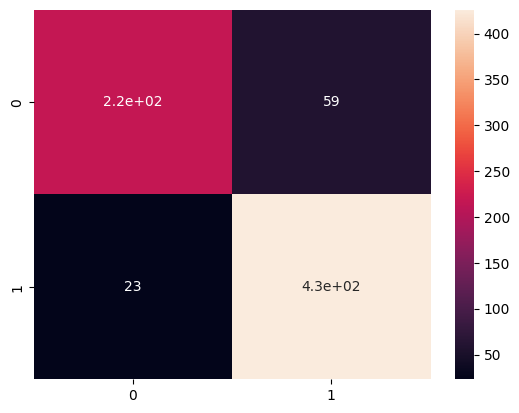

In [36]:
classification_report(ytest,y_pred)
cm=confusion_matrix(ytest,y_pred)
sns.heatmap(cm,annot=True)
plt.show()

Fitting 5 folds for each of 4 candidates, totalling 20 fits
{'n_estimators': np.int64(400)} 0.8870538310878985
              precision    recall  f1-score   support

           0     0.9069    0.8087    0.8550       277
           1     0.8894    0.9488    0.9181       449

    accuracy                         0.8953       726
   macro avg     0.8981    0.8787    0.8865       726
weighted avg     0.8960    0.8953    0.8940       726



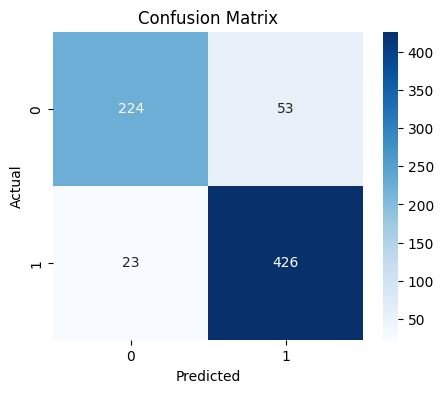

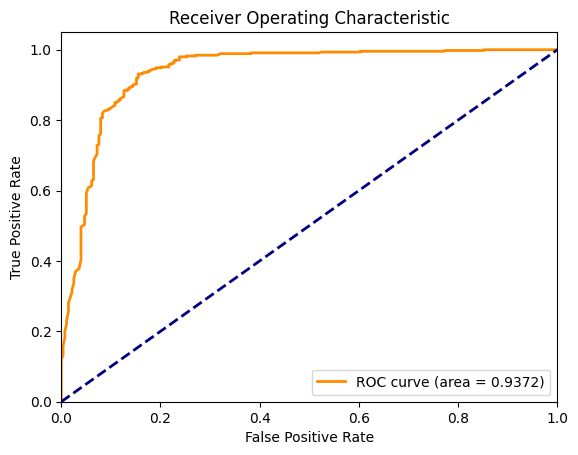

In [38]:
model = RandomForestClassifier(random_state=42)
params = {'n_estimators': np.arange(100,500,100)}
cv_rf = GridSearchCV(model, param_grid=params, scoring="accuracy", n_jobs=-1, cv=5,verbose=3)
cv_rf.fit(xtrain, ytrain)
best_RF=cv_rf.best_estimator_
y_pred = best_RF.predict(xtest)
print(cv_rf.best_params_, cv_rf.best_score_)
# Need to print the classiiofcation report , confusion matrix using heatmap

import matplotlib.pyplot as plt

print(classification_report(ytest, y_pred,digits=4))

cm = confusion_matrix(ytest, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#  Draw the roc curev and auc using the results of random forest
# ROC Curve and AUC
y_pred_proba = best_RF.predict_proba(xtest)[:, 1]
fpr, tpr, thresholds = roc_curve(ytest, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.4f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import GridSearchCV


eclf = VotingClassifier(estimators=[
    ('svm', SVC(probability=True)),
    ('lr', LogisticRegression()),
    # ('rf', RandomForestClassifier()),
    # ('dt', DecisionTreeClassifier())
    ], voting='soft')

#Use the key for the classifier followed by __ and the attribute
params = {'lr__C': [1.0, 100.0],
      'svm__C': [2,3,4],}

grid = GridSearchCV(estimator=eclf, param_grid=params, cv=5,n_jobs=-1, verbose=3)

grid.fit(xtrain,ytrain)
print (grid.best_params_)
best_VC=grid.best_estimator_
y_pred=best_VC.predict(xtest)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
{'lr__C': 100.0, 'svm__C': 3}


              precision    recall  f1-score   support

           0     0.9139    0.8051    0.8560       277
           1     0.8880    0.9532    0.9194       449

    accuracy                         0.8967       726
   macro avg     0.9010    0.8791    0.8877       726
weighted avg     0.8979    0.8967    0.8953       726



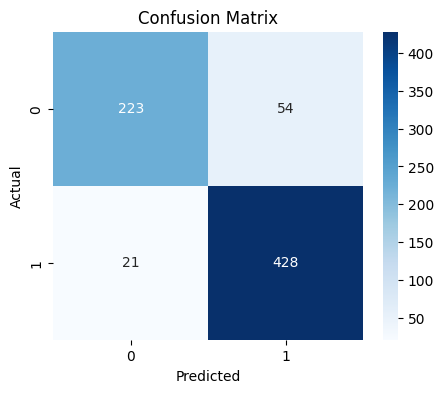

NameError: name 'X_test' is not defined

In [40]:
# Need to print the classiiofcation report , confusion matrix using heatmap

import matplotlib.pyplot as plt

print(classification_report(ytest, y_pred,digits=4))

cm = confusion_matrix(ytest, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#  Draw the roc curev and auc using the results of random forest
# ROC Curve and AUC
y_pred_proba = best_VC.predict_proba(xtest)[:, 1]
fpr, tpr, thresholds = roc_curve(ytest, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.4f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()